# 14 · Flow diagnostics: time of flight, tracer partitions, F–Φ, Lorenz and sweep

Flow diagnostics answer "where does the injected fluid go, and how fast?" from **one** pressure solve, without
time stepping. From a converged flux field SubsurfiX computes:

- **Time of flight (TOF).** Forward TOF is the time fluid needs to reach a cell from an injector. Backward TOF is
  the time it needs to get from the cell to a producer. Their sum is the cell's total travel time (residence time).
- **Tracer partitions.** These are the share of each cell's fluid that comes from each injector or goes to each
  producer. Each cell's shares add up to one, and the largest share gives the drainage and flooded regions.
- **Well pairs.** These are the pore volume each injector–producer pair sweeps, and how each well's rate splits
  between its partner wells (allocation).
- **F–Φ, Lorenz coefficient and sweep.** Flow capacity is plotted against storage capacity. The Lorenz
  coefficient is 0 for a perfectly even displacement and approaches 1 for strongly channelled flow. Sweep
  efficiency is plotted against pore volumes injected.

The methods are ported from MRST's `diagnostics` module (Shahvali et al. 2012; Møyner, Krogstad and Lie 2015;
GPL-3.0-or-later, see `NOTICE`). They run as compiled Rust using one upwind finite-volume operator and one
sparse LU per direction.

**Current method stays the default.** The time-stepped tracer (`FlowModel.run_tracer`) is still the default way
to get a producer tracer response. `subsurfix.diagnostics.producer_tracer_response(..., method="tof")` is the new
option. This notebook runs **both** on the same flux field and compares them.

Three models are used, all from earlier notebooks:
1. the layered block model of notebooks 09, 10 and 12 (`block_model.py`);
2. the whole Kansas (KGS) property model of the same notebooks (`kansas_window.py`, small committed data);
3. a smaller version of notebook 13's faulted corner-point block.

All numbers and figures below come from the compiled solvers run in this notebook.

In [1]:
%matplotlib inline
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import subsurfix as sx
from block_model import describe, layered_block
from IPython.display import Markdown, display
from kansas_window import kansas_model
from subsurfix import _native as nat
from subsurfix import diagnostics as dg

OUT = Path(os.environ.get("SX_EXAMPLE_OUT", "outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
YR = 365.25 * 86400.0
MU_W = 1e-3                      # water viscosity (Pa s) for the single-phase flux field
RATE = 0.01                      # injector rate (m3/s)

## Helpers
Each model gets one injector in the middle and two producers in opposite corners, and every well is open in all
layers. Every model then goes through the same steps:
1. Run flow diagnostics on the single-phase pressure solution.
2. Run the default time-stepped tracer and the TOF prediction for the producer response, on the same flux field.
3. Make the maps and the F–Φ and sweep plots.

In [2]:
def wells_for(dims, inj, prods, rate=RATE, bhp=2.0e7):
    nx, ny, nz = dims
    col = lambda i, j: [i + nx * (j + ny * k) for k in range(nz)]
    w = [{"name": "INJ", "kind": "injector", "rate": rate, "cells": col(*inj)}]
    for n_, (i, j) in enumerate(prods, 1):
        w.append({"name": f"PROD{n_}", "kind": "producer", "bhp": bhp, "cells": col(i, j)})
    return w


def first_time(t, c, level):
    i = np.argmax(c >= level)
    return t[i] if c[i] >= level else np.nan


def analyse(name, model, wells, t_end_pv=3.0, n_t=121):
    mob = np.full(model.n_cells, 1.0 / MU_W)
    t0 = time.time(); d = dg.flow_diagnostics(model, mob, wells); t_diag = time.time() - t0
    pv = model.pore_volume(); q_in = sum(w["rate"] for w in wells if w["kind"] == "injector")
    times = np.linspace(0.0, t_end_pv * pv.sum() / q_in, n_t)
    t0 = time.time(); tr = dg.producer_tracer_response(model, mob, wells, times); t_tr = time.time() - t0
    t0 = time.time(); tf = dg.producer_tracer_response(model, mob, wells, times, method="tof"); t_tf = time.time() - t0
    part_sum = d["injector_tracer"].sum(axis=0) if len(d["injectors"]) else np.zeros(1)
    prod_sum = d["producer_tracer"].sum(axis=0)
    act = np.isfinite(d["tof_forward"])
    capped = act & ((d["tof_forward"] >= d["max_tof"]) | (d["tof_backward"] >= d["max_tof"]))
    reach = act & (d["tof_forward"] + d["tof_backward"] < 0.1 * d["max_tof"])
    return {"name": name, "d": d, "times": times, "tr": tr, "tf": tf, "t_diag": t_diag, "t_tr": t_tr, "t_tf": t_tf,
            "tracer_sum_err": float(np.nanmax(np.abs(prod_sum[reach] - 1.0))), "inj_sum_err": float(np.nanmax(np.abs(part_sum[reach] - 1.0))),
            "pv": pv, "q_in": q_in, "reach": reach, "n_capped": int(capped.sum())}


def summary_table(rs):
    rows = ["| Model | Lorenz | Ev at 1 PVI | Diagnostics run time | Cells at the TOF cap | Max abs(Σ tracer − 1), inj / prod |", "|---|---|---|---|---|---|"]
    for r in rs:
        d = r["d"]; ev = np.interp(1.0, d["tD"], d["Ev"])
        rows.append(f"| {r['name']} | {d['lorenz']:.3f} | {ev:.3f} | {r['t_diag']:.2f} s | {r['n_capped']} | {r['inj_sum_err']:.1e} / {r['tracer_sum_err']:.1e} |")
    return "\n".join(rows)


def compare_table(rs):
    rows = ["| Model | Method | 1 % arrival (yr) | 10 % (yr) | 50 % (yr) | Run time | Explicit steps |", "|---|---|---|---|---|---|---|"]
    for r in rs:
        for lab, x, rt in (("run_tracer (default)", r["tr"], r["t_tr"]), ("TOF (option)", r["tf"], r["t_tf"])):
            v = [first_time(r["times"], x["conc"], lv) / YR for lv in (0.01, 0.10, 0.50)]
            rows.append(f"| {r['name']} | {lab} | {v[0]:.0f} | {v[1]:.0f} | {v[2]:.0f} | {rt:.2f} s | {x.get('n_steps', '–')} |")
    return "\n".join(rows)


def pairs_table(rs):
    rows = ["| Model | Pair | Pair pore volume (% of total) | Injector rate to producer (%) |", "|---|---|---|---|"]
    for r in rs:
        tot = r["pv"].sum()
        for p in r["d"]["well_pairs"]:
            rows.append(f"| {r['name']} | {p['injector']} → {p['producer']} | {100 * p['pore_volume'] / tot:.1f} | {100 * p['injector_allocation'] / r['q_in']:.1f} |")
    return "\n".join(rows)


def maps(r, dims, layer, fname):
    nx, ny, _ = dims; d = r["d"]
    sl = slice(layer * nx * ny, (layer + 1) * nx * ny)
    fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
    for a, v, title in ((ax[0], d["tof_forward"], "forward TOF (yr)"), (ax[1], d["tof_backward"], "backward TOF (yr)"),
                        (ax[2], d["tof_forward"] + d["tof_backward"], "total travel time (yr)")):
        im = a.imshow(np.log10(v[sl].reshape(ny, nx) / YR), origin="lower", cmap="viridis")
        a.set_title(title + ", log10", fontsize=9); fig.colorbar(im, ax=a, shrink=0.8)
    im = ax[3].imshow(d["producer_partition"][sl].reshape(ny, nx), origin="lower", cmap="Set2", vmin=-1, vmax=2)
    ax[3].set_title("producer partition (0 = PROD1, 1 = PROD2)", fontsize=9)
    for a in ax: a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{r['name']}: layer {layer}", fontsize=10)
    fig.savefig(OUT / fname, bbox_inches="tight")


def curves(rs, fname):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    for r in rs:
        d = r["d"]
        ax[0].plot(d["Phi"], d["F"], label=f"{r['name']} (Lc {d['lorenz']:.2f})")
        ax[1].plot(d["tD"], d["Ev"], label=r["name"])
        l, = ax[2].plot(r["times"] / YR, r["tr"]["conc"], label=f"{r['name']}: run_tracer")
        ax[2].plot(r["times"] / YR, r["tf"]["conc"], "--", color=l.get_color(), label=f"{r['name']}: TOF")
    ax[0].plot([0, 1], [0, 1], "k:", lw=0.8); ax[0].set_xlabel("Φ (storage capacity)"); ax[0].set_ylabel("F (flow capacity)")
    ax[1].set_xlim(0, 3); ax[1].set_xlabel("dimensionless time (PVI)"); ax[1].set_ylabel("sweep efficiency Ev")
    ax[2].set_xlabel("years"); ax[2].set_ylabel("produced tracer concentration")
    for a in ax: a.legend(fontsize=7)
    fig.savefig(OUT / fname, bbox_inches="tight")

## 1 · Layered block model
The block model has 10 × 10 × 12 cells of 500 × 500 × 5 m and four units with permeabilities from 0.5 to 80 mD.
INJ is at (5, 5), PROD1 at (1, 1) and PROD2 at (8, 8), and all three are open in every layer.

| Unit | Layers | Porosity | k (mD) |
|---|---|---|---|
| upper sand | 0–2 | 0.12 | 5 |
| main sand | 3–5 | 0.22 | 80 |
| shaly baffle | 6–8 | 0.06 | 0.5 |
| lower sand | 9–11 | 0.16 | 20 |

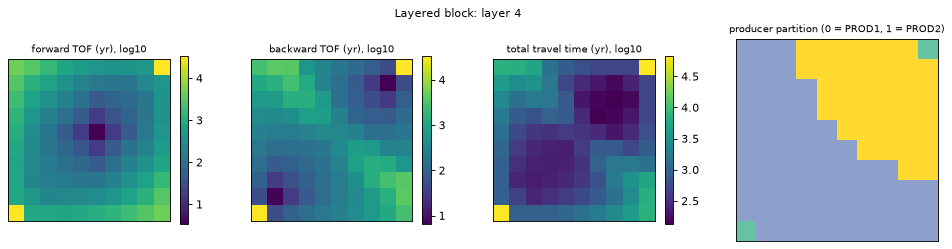

In [3]:
blk = layered_block()
display(Markdown(describe(blk)))
m_blk = nat.FlowModel.from_regular(blk["origin"], blk["cell"], blk["dims"], blk["perm"], blk["phi"])
w_blk = wells_for(blk["dims"], (5, 5), [(1, 1), (8, 8)])
r_blk = analyse("Layered block", m_blk, w_blk)
maps(r_blk, blk["dims"], 4, "nb14_block_maps.png")

### Multiphase state (fully implicit total flux)
The water–oil fully implicit (FIM) run from notebook 12 runs here for 5 years on the same wells. Its water
saturation fixes each cell's total mobility λt = krw/μw + kro/μo (Corey, the solver's own curves). Diagnostics on
that frozen-mobility total-flux field show how the injected water bank changes the flow pattern compared with
the single-phase field.

In [4]:
COREY = {"mu_o": 2e-3}
t0 = time.time()
fim = nat.run_fim_water_oil(m_blk, w_blk, np.full(m_blk.n_cells, 0.2), np.full(m_blk.n_cells, 2e7), [5 * YR],
                            corey=COREY, physics={"c_w": 4e-10, "c_o": 1e-9}, p_range=(5e6, 5e7),
                            table_points=(31, 201), dt_init=86400.0, dt_max=0.25 * YR)
t_fim = time.time() - t0
sw = np.asarray(fim["saturation"])[-1, :, 0]
lam = dg.total_mobility(sw, COREY)
d_fim = dg.flow_diagnostics(m_blk, lam, w_blk)
d_1p = r_blk["d"]
inj_cells = w_blk[0]["cells"]
rows = ["| Flux field | Lorenz | Ev at 1 PVI | INJ → PROD1 allocation (%) | Median total travel time (yr) |", "|---|---|---|---|---|"]
for lab, d in (("single phase (water)", d_1p), ("FIM water–oil at 5 yr, frozen λt", d_fim)):
    tau = d["tof_forward"] + d["tof_backward"]
    a1 = 100 * d["well_pairs"][0]["injector_allocation"] / RATE
    rows.append(f"| {lab} | {d['lorenz']:.3f} | {np.interp(1, d['tD'], d['Ev']):.3f} | {a1:.1f} | {np.median(tau) / YR:.0f} |")
display(Markdown(f"FIM run: {t_fim:.1f} s, {fim['n_steps']} steps, max Sw {sw.max():.3f}.\n\n" + "\n".join(rows)))

FIM run: 7.8 s, 30 steps, max Sw 0.635.

| Flux field | Lorenz | Ev at 1 PVI | INJ → PROD1 allocation (%) | Median total travel time (yr) |
|---|---|---|---|---|
| single phase (water) | 0.621 | 0.526 | 48.0 | 3995 |
| FIM water–oil at 5 yr, frozen λt | 0.593 | 0.551 | 48.0 | 2843 |

## 2 · Whole Kansas (KGS) property model
This is the whole KGS property model used in notebooks 09, 10 and 12: 22 × 22 × 12 cells of 500 × 500 × 5 m
(11 × 11 km, 60 m thick), with permeability taken from porosity. INJ is in the middle at (11, 11) and the
producers are at (7, 7) and (15, 15), each about 2.8 km from INJ on the diagonal, so the layout matches the
block model scaled up and any difference between the two producers comes from the real heterogeneity.

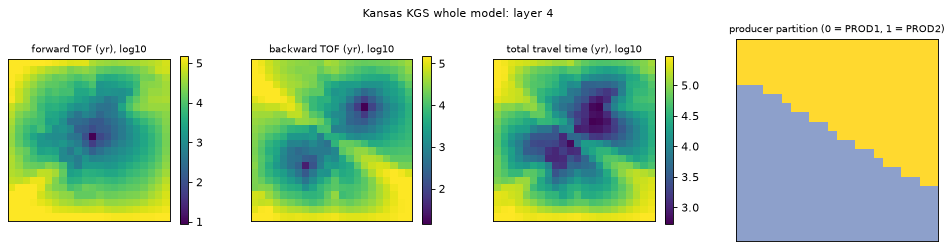

In [5]:
ks = kansas_model()
m_ks = nat.FlowModel.from_regular(ks["origin"], ks["cell"], ks["dims"], ks["perm"], ks["phi"])
w_ks = wells_for(ks["dims"], (11, 11), [(7, 7), (15, 15)])
r_ks = analyse("Kansas KGS whole model", m_ks, w_ks)
maps(r_ks, ks["dims"], 4, "nb14_kansas_maps.png")

## 3 · Faulted corner-point block
This is a 20 × 12 × 6 version of notebook 13's block, with 50 × 50 m cells, a 2 % dip, alternating 200 and
50 mD layers, and a 10 m normal throw at x = 500 m. INJ is in the upthrown block, and both producers are in the
downthrown block. All flow to the producers crosses the fault through overlap connections.

Fault connections: 84; flux across x = 500 m: 0.00200 m³/s (injection 0.00200 m³/s).

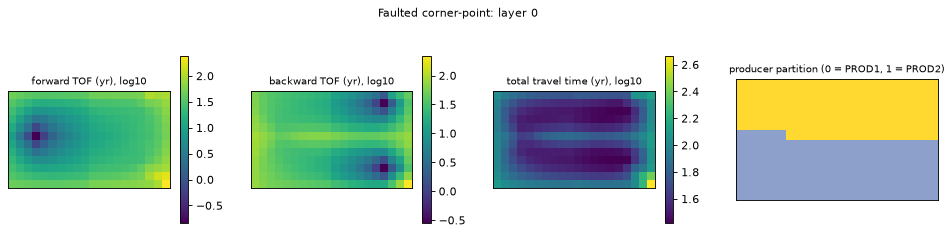

In [6]:
NX, NY, NZ, D, DZ = 20, 12, 6, 50.0, 4.0
xs, ys = np.arange(NX + 1) * D, np.arange(NY + 1) * D
X, Y = np.meshgrid(xs, ys)
top = 1000.0 + 0.02 * X
surf = np.array([(top + k * DZ).ravel() for k in range(NZ + 1)])
g0 = nat.CornerPointGrid.from_surfaces(xs, ys, surf)
z = np.array(g0.zcorn, dtype=float)
z[(np.arange(z.size) % (2 * NX)) >= 2 * 10] += 10.0
grid = nat.CornerPointGrid(g0.dims, np.array(g0.coord), z, None)
kk = np.repeat(np.where(np.arange(NZ) % 2 == 0, 200.0, 50.0), NX * NY) * 9.869233e-16
phi = np.repeat(np.where(np.arange(NZ) % 2 == 0, 0.24, 0.18), NX * NY)
m_cp = nat.FlowModel.from_corner_point(grid, np.column_stack([kk, kk, 0.1 * kk]), phi)
w_cp = wells_for((NX, NY, NZ), (3, 6), [(16, 2), (16, 10)], rate=0.002)
r_cp = analyse("Faulted corner-point", m_cp, w_cp)
a, b, _ = sx.transmissibilities(m_cp)
flux = r_cp["d"]["flux"]
cross = ((a % NX) < 10) != ((b % NX) < 10)
display(Markdown(f"Fault connections: {m_cp.n_fault_connections}; flux across x = 500 m: "
                 f"{np.abs(flux[cross]).sum():.5f} m³/s (injection {w_cp[0]["rate"]:.5f} m³/s)."))
maps(r_cp, (NX, NY, NZ), 0, "nb14_faulted_maps.png")

## Results
### Diagnostics summary
The last column is the self-check that each cell's injector shares and producer shares add up to one. It is taken
over cells whose total travel time is below 10 % of the TOF cap (50 × total PV / injection rate).

Cells at the cap are stagnant, for example in the 0.5 mD baffle away from the wells. As in MRST, they get the cap
value and pass no tracer downstream. Cells next to them can therefore lose part of their inflow, so their tracer
sum can be below one. On the whole Kansas model 823 of 5808 cells are at the cap (far corners and low-k
cells), and the check is about 2e-4 instead of round-off.

In [7]:
RS = [r_blk, r_ks, r_cp]
display(Markdown(summary_table(RS)))

| Model | Lorenz | Ev at 1 PVI | Diagnostics run time | Cells at the TOF cap | Max abs(Σ tracer − 1), inj / prod |
|---|---|---|---|---|---|
| Layered block | 0.621 | 0.526 | 0.04 s | 108 | 1.8e-11 / 2.0e-11 |
| Kansas KGS whole model | 0.805 | 0.341 | 0.09 s | 823 | 1.7e-04 / 1.9e-04 |
| Faulted corner-point | 0.291 | 0.788 | 0.01 s | 0 | 1.3e-15 / 8.9e-16 |

### Well pairs and allocation

In [8]:
display(Markdown(pairs_table(RS)))

| Model | Pair | Pair pore volume (% of total) | Injector rate to producer (%) |
|---|---|---|---|
| Layered block | INJ → PROD1 | 61.2 | 48.0 |
| Layered block | INJ → PROD2 | 35.7 | 52.0 |
| Kansas KGS whole model | INJ → PROD1 | 48.2 | 35.5 |
| Kansas KGS whole model | INJ → PROD2 | 51.3 | 64.5 |
| Faulted corner-point | INJ → PROD1 | 53.0 | 51.4 |
| Faulted corner-point | INJ → PROD2 | 47.0 | 48.6 |

### Producer tracer response: run_tracer (default) vs TOF (option)
Both methods use the same flux field. Unit tracer enters at INJ, and the curve is the flux-weighted concentration
at the producers.
- `run_tracer` is the explicit time-stepped upwind tracer. It is cheap per step but needs many steps, and its
  numerical dispersion smears the front.
- TOF predicts the response from total travel times, with no time stepping and no numerical dispersion.

What to expect on these coarse grids, where only 3–8 cells separate the wells: the explicit tracer arrives
earlier at every level, because numerical dispersion spreads the front over several cells. TOF has no dispersion
but adds about half a cell of lag at each end. The two converge as the grid is refined (the 1D validation test
gives TOF = PV/q exactly).

| Model | Method | 1 % arrival (yr) | 10 % (yr) | 50 % (yr) | Run time | Explicit steps |
|---|---|---|---|---|---|---|
| Layered block | run_tracer (default) | 67 | 100 | 266 | 0.02 s | 720 |
| Layered block | TOF (option) | 150 | 166 | 366 | 0.02 s | – |
| Kansas KGS whole model | run_tracer (default) | 150 | 150 | 449 | 0.67 s | 10920 |
| Kansas KGS whole model | TOF (option) | 224 | 299 | 823 | 0.08 s | – |
| Faulted corner-point | run_tracer (default) | 14 | 20 | 36 | 0.02 s | 1200 |
| Faulted corner-point | TOF (option) | 28 | 31 | 47 | 0.01 s | – |

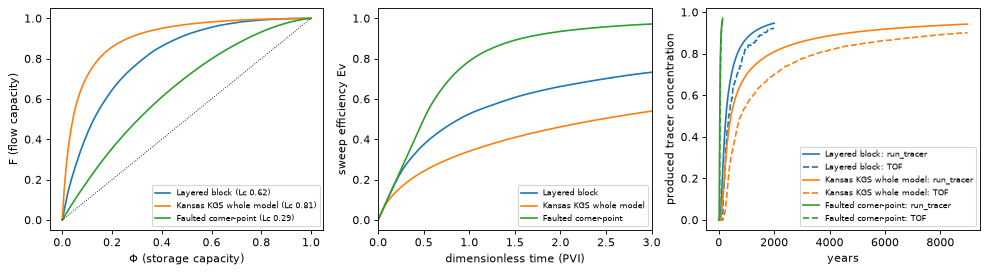

In [9]:
display(Markdown(compare_table(RS)))
curves(RS, "nb14_fphi_sweep_response.png")

## What the numbers mean
- **Lorenz coefficient.** The block model's layering gives a clear contrast between flow capacity and storage
  capacity. The KGS model adds lateral heterogeneity on top of that. The faulted block has only two layer
  permeabilities, so its value is lower.
- **Sweep.** Ev at 1 PVI is the fraction of the pore volume contacted after one pore volume has been injected,
  assuming a unit-mobility-ratio displacement.
- **Allocation.** This shows which producer receives the injected water. It depends on well placement and on
  permeability paths. In the faulted block, all of it crosses the fault.
- **TOF vs run_tracer.** Both rank the models the same way (faulted block fastest, KGS model and block model
  slower). On these coarse grids `run_tracer` arrives earlier, by up to about 2.2× at 1 % and up to about 1.8× at
  50 %. That gap reflects numerical dispersion plus TOF's cell-centred lag, not different physics. Use TOF for fast
  ranking and screening, and `run_tracer` (the default) when the time-stepped response matters.
- **Multiphase.** Freezing the FIM water–oil state's total mobility shows how the water bank changes the flow
  pattern after 5 years.

## Limitations
- TOF is cell-centred, as in MRST, so a cell's total travel time counts the cell itself once in each direction.
  In a 1D line this makes the TOF breakthrough one cell late, i.e. (N + 1)/N × PV/q.
- Diagnostics are steady-state. Each one is a snapshot of one flux field (incompressible, with no gravity
  segregation inside the diagnostics). For multiphase states the total mobility is frozen.
- TOF is capped at 50 × total PV / injection rate. Stagnant cells above the cap get the cap and pass nothing
  downstream.
- Fixed-pressure inflow boundaries count as sources for TOF. Tracer partitions are computed only for wells.